Setup & Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

# >>> set this to your combined CSV path <<<
DATA_PATH = "dataset.csv"

Load the Dataset

In [3]:
df = pd.read_csv(
    DATA_PATH,
    parse_dates=["TX_DATETIME"],
    dtype={
        "TRANSACTION_ID": "int64",
        "CUSTOMER_ID": "category",
        "TERMINAL_ID": "category",
        "TX_AMOUNT": "float32",
        "TX_TIME_SECONDS": "int64",
        "TX_TIME_DAYS": "int32",
        "TX_FRAUD": "int8",
        "TX_FRAUD_SCENARIO": "int8",
    },
)

print(df.shape)
df.head()

(1754155, 9)


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO
0,0,2018-04-01 00:00:31,596,3156,57.160000,31,0,0,0
1,1,2018-04-01 00:02:10,4961,3412,81.510002,130,0,0,0
2,2,2018-04-01 00:07:56,2,1365,146.000000,476,0,0,0
3,3,2018-04-01 00:09:29,4128,8737,64.489998,569,0,0,0
4,4,2018-04-01 00:10:34,927,9906,50.990002,634,0,0,0


Check Memory Usage & Dtypes

In [4]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1754155 entries, 0 to 1754154
Data columns (total 9 columns):
 #   Column             Dtype         
---  ------             -----         
 0   TRANSACTION_ID     int64         
 1   TX_DATETIME        datetime64[us]
 2   CUSTOMER_ID        category      
 3   TERMINAL_ID        category      
 4   TX_AMOUNT          float32       
 5   TX_TIME_SECONDS    int64         
 6   TX_TIME_DAYS       int32         
 7   TX_FRAUD           int8          
 8   TX_FRAUD_SCENARIO  int8          
dtypes: category(2), datetime64[us](1), float32(1), int32(1), int64(2), int8(2)
memory usage: 64.1 MB


Validation Checks

In [5]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate TRANSACTION_IDs:", df["TRANSACTION_ID"].duplicated().sum())
print("\nTX_AMOUNT <= 0 count:", (df["TX_AMOUNT"] <= 0).sum())
print("Date range:", df["TX_DATETIME"].min(), "to", df["TX_DATETIME"].max())

Missing values:
 TRANSACTION_ID       0
TX_DATETIME          0
CUSTOMER_ID          0
TERMINAL_ID          0
TX_AMOUNT            0
TX_TIME_SECONDS      0
TX_TIME_DAYS         0
TX_FRAUD             0
TX_FRAUD_SCENARIO    0
dtype: int64

Duplicate rows: 0
Duplicate TRANSACTION_IDs: 0

TX_AMOUNT <= 0 count: 42
Date range: 2018-04-01 00:00:31 to 2018-09-30 23:59:57


Inspect the zero/negative amount rows

In [6]:
df[df["TX_AMOUNT"] <= 0]

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO
129590,129590,2018-04-14 12:04:05,4741,2134,0.0,1166645,13,0,0
187419,187419,2018-04-20 12:55:28,3224,9252,0.0,1688128,19,0,0
207512,207512,2018-04-22 13:56:47,3411,5627,0.0,1864607,21,0,0
238779,238779,2018-04-25 18:12:14,2312,187,0.0,2139134,24,0,0
303728,303728,2018-05-02 13:56:34,3470,9478,0.0,2728594,31,0,0
343034,343034,2018-05-06 15:20:43,1611,6006,0.0,3079243,35,0,0
344954,344954,2018-05-06 19:50:08,1828,9290,0.0,3095408,35,0,0
373190,373190,2018-05-09 18:15:02,3746,566,0.0,3348902,38,0,0
413360,413360,2018-05-14 04:16:16,2494,9755,0.0,3730576,43,0,0
441108,441108,2018-05-16 20:34:15,4717,1475,0.0,3962055,45,0,0


Drop the zero-amount rows

In [7]:
df = df[df["TX_AMOUNT"] > 0].reset_index(drop=True)
print(df.shape)

(1754113, 9)


Sort by Timestamp

In [8]:
df = df.sort_values("TX_DATETIME").reset_index(drop=True)
df.set_index("TX_DATETIME", inplace=True, drop=False)
df.index.name = "TX_DATETIME_IDX"
df = df.reset_index(drop=True)
df.head()

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO
0,0,2018-04-01 00:00:31,596,3156,57.160000,31,0,0,0
1,1,2018-04-01 00:02:10,4961,3412,81.510002,130,0,0,0
2,2,2018-04-01 00:07:56,2,1365,146.000000,476,0,0,0
3,3,2018-04-01 00:09:29,4128,8737,64.489998,569,0,0,0
4,4,2018-04-01 00:10:34,927,9906,50.990002,634,0,0,0


Fraud Distribution

TX_FRAUD
0    1739432
1      14681
Name: count, dtype: int64
Fraud rate: 0.837%


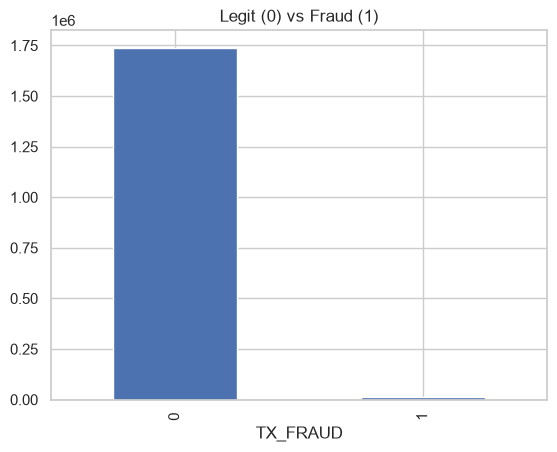

In [9]:
fraud_counts = df["TX_FRAUD"].value_counts()
fraud_rate = df["TX_FRAUD"].mean() * 100
print(fraud_counts)
print(f"Fraud rate: {fraud_rate:.3f}%")

fraud_counts.plot(kind="bar", title="Legit (0) vs Fraud (1)")
plt.show()

Transaction Amount: Legit vs Fraud

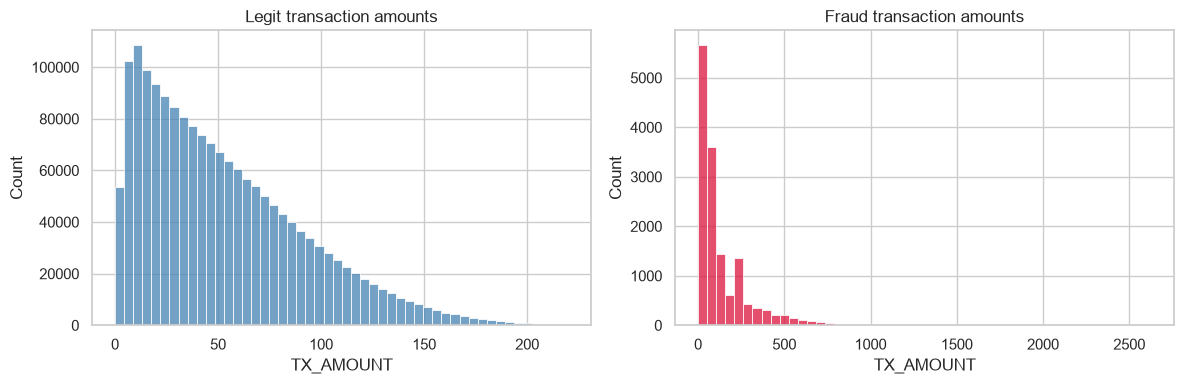

,count,mean,std,min,25%,50%,75%,max
TX_FRAUD,,,,,,,,
0,1739432.0,52.979187,39.421349,0.01,20.940001,44.490002,76.629997,219.979996
1,14681.0,131.168030,154.485794,0.02,32.980000,72.220001,177.300003,2628.000000


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[df.TX_FRAUD == 0]["TX_AMOUNT"], bins=50, ax=ax[0], color="steelblue")
ax[0].set_title("Legit transaction amounts")
sns.histplot(df[df.TX_FRAUD == 1]["TX_AMOUNT"], bins=50, ax=ax[1], color="crimson")
ax[1].set_title("Fraud transaction amounts")
plt.tight_layout()
plt.show()

df.groupby("TX_FRAUD")["TX_AMOUNT"].describe()

Time Patterns

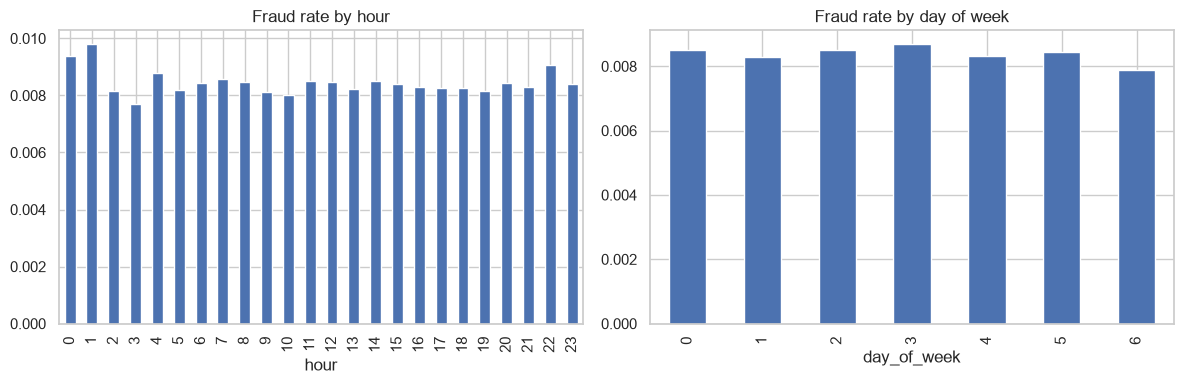

In [11]:
df["hour"] = df["TX_DATETIME"].dt.hour
df["day_of_week"] = df["TX_DATETIME"].dt.dayofweek
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype("int8")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("hour")["TX_FRAUD"].mean().plot(kind="bar", ax=ax[0], title="Fraud rate by hour")
df.groupby("day_of_week")["TX_FRAUD"].mean().plot(kind="bar", ax=ax[1], title="Fraud rate by day of week")
plt.tight_layout()
plt.show()

Fraud Scenario Breakdown

In [12]:
df["TX_FRAUD_SCENARIO"].value_counts().sort_index()

TX_FRAUD_SCENARIO
0    1739432
1        973
2       9077
3       4631
Name: count, dtype: int64

Customer & Terminal Activity Volume

In [13]:
cust_counts = df["CUSTOMER_ID"].value_counts()
term_counts = df["TERMINAL_ID"].value_counts()

print("Transactions per customer — describe:")
print(cust_counts.describe())
print("\nTransactions per terminal — describe:")
print(term_counts.describe())

Transactions per customer — describe:
count    4990.000000
mean      351.525651
std       205.103061
min         1.000000
25%       174.000000
50%       347.000000
75%       531.000000
max       767.000000
Name: count, dtype: float64

Transactions per terminal — describe:
count    10000.000000
mean       175.411300
std         39.170187
min         47.000000
25%        148.000000
50%        171.000000
75%        199.000000
max        376.000000
Name: count, dtype: float64


### **Feature Engineering**

Transaction-level features (amount transform)

In [14]:
df["log_amount"] = np.log1p(df["TX_AMOUNT"])

df[["TX_AMOUNT", "log_amount"]].describe()

,TX_AMOUNT,log_amount
count,1.754113e+06,1.754113e+06
mean,5.363358e+01,3.659614e+00
std,4.232619e+01,9.208086e-01
min,1.000000e-02,9.950330e-03
25%,2.101000e+01,3.091497e+00
50%,4.464000e+01,3.820785e+00
75%,7.695000e+01,4.356068e+00
max,2.628000e+03,7.874359e+00


Customer Rolling Transaction Counts

In [15]:
def rolling_count_by_time(group, window):
    s = group.set_index("TX_DATETIME")["TX_AMOUNT"]
    counts = s.rolling(window, closed="left").count()
    return pd.Series(counts.values, index=group.index)

df["cust_txn_count_1h"] = df.groupby("CUSTOMER_ID", group_keys=False).apply(
    lambda g: rolling_count_by_time(g, "1h")
)

df["cust_txn_count_24h"] = df.groupby("CUSTOMER_ID", group_keys=False).apply(
    lambda g: rolling_count_by_time(g, "24h")
)

df["cust_txn_count_7d"] = df.groupby("CUSTOMER_ID", group_keys=False).apply(
    lambda g: rolling_count_by_time(g, "7D")
)

df[["CUSTOMER_ID", "TX_DATETIME", "cust_txn_count_1h", "cust_txn_count_24h", "cust_txn_count_7d"]].head(15)

,CUSTOMER_ID,TX_DATETIME,cust_txn_count_1h,cust_txn_count_24h,cust_txn_count_7d
0,596,2018-04-01 00:00:31,NaN,NaN,NaN
1,4961,2018-04-01 00:02:10,NaN,NaN,NaN
2,2,2018-04-01 00:07:56,NaN,NaN,NaN
3,4128,2018-04-01 00:09:29,NaN,NaN,NaN
4,927,2018-04-01 00:10:34,NaN,NaN,NaN
5,568,2018-04-01 00:10:45,NaN,NaN,NaN
6,2803,2018-04-01 00:11:30,NaN,NaN,NaN
7,4684,2018-04-01 00:11:44,NaN,NaN,NaN
8,4128,2018-04-01 00:11:53,1.0,1.0,1.0
9,541,2018-04-01 00:13:44,NaN,NaN,NaN


Customer Average Amount & Time Since Last Transaction

In [16]:
def rolling_mean_by_time(group, window):
    s = group.set_index("TX_DATETIME")["TX_AMOUNT"]
    means = s.rolling(window, closed="left").mean()
    return pd.Series(means.values, index=group.index)

df["cust_avg_amount_7d"] = df.groupby("CUSTOMER_ID", group_keys=False).apply(
    lambda g: rolling_mean_by_time(g, "7D")
)

df["time_since_cust_prev_txn"] = (
    df.groupby("CUSTOMER_ID")["TX_DATETIME"]
      .diff()
      .dt.total_seconds()
)

df[["CUSTOMER_ID", "TX_DATETIME", "cust_avg_amount_7d", "time_since_cust_prev_txn"]].head(15)

,CUSTOMER_ID,TX_DATETIME,cust_avg_amount_7d,time_since_cust_prev_txn
0,596,2018-04-01 00:00:31,NaN,NaN
1,4961,2018-04-01 00:02:10,NaN,NaN
2,2,2018-04-01 00:07:56,NaN,NaN
3,4128,2018-04-01 00:09:29,NaN,NaN
4,927,2018-04-01 00:10:34,NaN,NaN
5,568,2018-04-01 00:10:45,NaN,NaN
6,2803,2018-04-01 00:11:30,NaN,NaN
7,4684,2018-04-01 00:11:44,NaN,NaN
8,4128,2018-04-01 00:11:53,64.489998,144.0
9,541,2018-04-01 00:13:44,NaN,NaN


Amount Deviation

In [17]:
df["amount_vs_cust_avg"] = df["TX_AMOUNT"] / df["cust_avg_amount_7d"]

df[["CUSTOMER_ID", "TX_DATETIME", "TX_AMOUNT", "cust_avg_amount_7d", "amount_vs_cust_avg"]].head(15)

,CUSTOMER_ID,TX_DATETIME,TX_AMOUNT,cust_avg_amount_7d,amount_vs_cust_avg
0,596,2018-04-01 00:00:31,57.160000,NaN,NaN
1,4961,2018-04-01 00:02:10,81.510002,NaN,NaN
2,2,2018-04-01 00:07:56,146.000000,NaN,NaN
3,4128,2018-04-01 00:09:29,64.489998,NaN,NaN
4,927,2018-04-01 00:10:34,50.990002,NaN,NaN
5,568,2018-04-01 00:10:45,44.709999,NaN,NaN
6,2803,2018-04-01 00:11:30,96.029999,NaN,NaN
7,4684,2018-04-01 00:11:44,24.360001,NaN,NaN
8,4128,2018-04-01 00:11:53,26.340000,64.489998,0.408435
9,541,2018-04-01 00:13:44,59.070000,NaN,NaN


Terminal Rolling Transaction Counts

In [18]:
df["term_txn_count_1h"] = df.groupby("TERMINAL_ID", group_keys=False).apply(
    lambda g: rolling_count_by_time(g, "1h")
)

df["term_txn_count_24h"] = df.groupby("TERMINAL_ID", group_keys=False).apply(
    lambda g: rolling_count_by_time(g, "24h")
)

df["term_txn_count_7d"] = df.groupby("TERMINAL_ID", group_keys=False).apply(
    lambda g: rolling_count_by_time(g, "7D")
)

df[["TERMINAL_ID", "TX_DATETIME", "term_txn_count_1h", "term_txn_count_24h", "term_txn_count_7d"]].head(15)

,TERMINAL_ID,TX_DATETIME,term_txn_count_1h,term_txn_count_24h,term_txn_count_7d
0,3156,2018-04-01 00:00:31,NaN,NaN,NaN
1,3412,2018-04-01 00:02:10,NaN,NaN,NaN
2,1365,2018-04-01 00:07:56,NaN,NaN,NaN
3,8737,2018-04-01 00:09:29,NaN,NaN,NaN
4,9906,2018-04-01 00:10:34,NaN,NaN,NaN
5,8803,2018-04-01 00:10:45,NaN,NaN,NaN
6,5490,2018-04-01 00:11:30,NaN,NaN,NaN
7,2486,2018-04-01 00:11:44,NaN,NaN,NaN
8,8354,2018-04-01 00:11:53,NaN,NaN,NaN
9,6212,2018-04-01 00:13:44,NaN,NaN,NaN


Terminal Average Amount

In [19]:
df["term_avg_amount_7d"] = df.groupby("TERMINAL_ID", group_keys=False).apply(lambda g: rolling_mean_by_time(g, "7D"))
df[["TERMINAL_ID", "TX_DATETIME", "TX_AMOUNT", "term_avg_amount_7d"]].head(15)

,TERMINAL_ID,TX_DATETIME,TX_AMOUNT,term_avg_amount_7d
0,3156,2018-04-01 00:00:31,57.160000,NaN
1,3412,2018-04-01 00:02:10,81.510002,NaN
2,1365,2018-04-01 00:07:56,146.000000,NaN
3,8737,2018-04-01 00:09:29,64.489998,NaN
4,9906,2018-04-01 00:10:34,50.990002,NaN
5,8803,2018-04-01 00:10:45,44.709999,NaN
6,5490,2018-04-01 00:11:30,96.029999,NaN
7,2486,2018-04-01 00:11:44,24.360001,NaN
8,8354,2018-04-01 00:11:53,26.340000,NaN
9,6212,2018-04-01 00:13:44,59.070000,NaN


Handling the NaNs

In [20]:
# Confirm where the NaNs actually are
print(df.isnull().sum())
print("\nTotal rows:", len(df))

TRANSACTION_ID                    0
TX_DATETIME                       0
CUSTOMER_ID                       0
TERMINAL_ID                       0
TX_AMOUNT                         0
TX_TIME_SECONDS                   0
TX_TIME_DAYS                      0
TX_FRAUD                          0
TX_FRAUD_SCENARIO                 0
hour                              0
day_of_week                       0
is_weekend                        0
log_amount                        0
cust_txn_count_1h           1531421
cust_txn_count_24h           216551
cust_txn_count_7d              9525
cust_avg_amount_7d             9525
time_since_cust_prev_txn       4990
amount_vs_cust_avg             9525
term_txn_count_1h           1663001
term_txn_count_24h           660996
term_txn_count_7d             13541
term_avg_amount_7d            13541
dtype: int64

Total rows: 1754113


In [21]:
# Count-based features: no history = 0 transactions, not missing data
count_cols = [
    "cust_txn_count_1h", "cust_txn_count_24h", "cust_txn_count_7d",
    "term_txn_count_1h", "term_txn_count_24h", "term_txn_count_7d",
]
df[count_cols] = df[count_cols].fillna(0)

# Time-since-last-transaction: no previous transaction = treat as "a long time", not 0
df["time_since_cust_prev_txn"] = df["time_since_cust_prev_txn"].fillna(df["time_since_cust_prev_txn"].max())

# Average amount: no history yet = fall back to this transaction's own amount
df["cust_avg_amount_7d"] = df["cust_avg_amount_7d"].fillna(df["TX_AMOUNT"])
df["term_avg_amount_7d"] = df["term_avg_amount_7d"].fillna(df["TX_AMOUNT"])

# Recompute amount_vs_cust_avg now that cust_avg_amount_7d has no NaNs left
df["amount_vs_cust_avg"] = df["TX_AMOUNT"] / df["cust_avg_amount_7d"]

# Final check — should be all zeros now
print(df.isnull().sum())

TRANSACTION_ID              0
TX_DATETIME                 0
CUSTOMER_ID                 0
TERMINAL_ID                 0
TX_AMOUNT                   0
TX_TIME_SECONDS             0
TX_TIME_DAYS                0
TX_FRAUD                    0
TX_FRAUD_SCENARIO           0
hour                        0
day_of_week                 0
is_weekend                  0
log_amount                  0
cust_txn_count_1h           0
cust_txn_count_24h          0
cust_txn_count_7d           0
cust_avg_amount_7d          0
time_since_cust_prev_txn    0
amount_vs_cust_avg          0
term_txn_count_1h           0
term_txn_count_24h          0
term_txn_count_7d           0
term_avg_amount_7d          0
dtype: int64


**Quick sanity check: do the new features actually differ by fraud label?**

In [22]:
feature_cols = [
    "log_amount", "hour", "is_weekend",
    "cust_txn_count_1h", "cust_txn_count_24h", "cust_txn_count_7d",
    "cust_avg_amount_7d", "time_since_cust_prev_txn", "amount_vs_cust_avg",
    "term_txn_count_1h", "term_txn_count_24h", "term_txn_count_7d", "term_avg_amount_7d",
]

df.groupby("TX_FRAUD")[feature_cols].mean()

,log_amount,hour,is_weekend,cust_txn_count_1h,cust_txn_count_24h,cust_txn_count_7d,cust_avg_amount_7d,time_since_cust_prev_txn,amount_vs_cust_avg,term_txn_count_1h,term_txn_count_24h,term_txn_count_7d,term_avg_amount_7d
TX_FRAUD,,,,,,,,,,,,,
0,3.654461,11.500703,0.289879,0.138541,2.560555,17.637686,53.456550,80544.379539,1.020619,0.053590,0.998001,6.869083,53.588604
1,4.270087,11.474763,0.282474,0.133302,2.561133,17.930727,72.382078,45692.866494,1.722662,0.053607,1.001090,7.011988,54.721559


**Temporal Train / Validation / Test Split**
- Data spans 2018-04-01 to 2018-09-30 (6 months). We'll split chronologically, with a delay gap between sets to simulate the real-world fact that fraud isn't confirmed/labeled instantly.

In [23]:
print("Date range:", df["TX_DATETIME"].min(), "to", df["TX_DATETIME"].max())

# Rough plan: ~4 months train, 7-day gap, ~3 weeks validation, 7-day gap, ~3 weeks test
train_end = pd.Timestamp("2018-08-01")
val_start = train_end + pd.Timedelta(days=7)
val_end = pd.Timestamp("2018-09-01")
test_start = val_end + pd.Timedelta(days=7)

print("Train:      up to", train_end)
print("Gap:        ", train_end, "to", val_start)
print("Validation: ", val_start, "to", val_end)
print("Gap:        ", val_end, "to", test_start)
print("Test:       ", test_start, "onward")

Date range: 2018-04-01 00:00:31 to 2018-09-30 23:59:57
Train:      up to 2018-08-01 00:00:00
Gap:         2018-08-01 00:00:00 to 2018-08-08 00:00:00
Validation:  2018-08-08 00:00:00 to 2018-09-01 00:00:00
Gap:         2018-09-01 00:00:00 to 2018-09-08 00:00:00
Test:        2018-09-08 00:00:00 onward


Apply the split

In [24]:
train_df = df[df["TX_DATETIME"] < train_end].copy()
val_df = df[(df["TX_DATETIME"] >= val_start) & (df["TX_DATETIME"] < val_end)].copy()
test_df = df[df["TX_DATETIME"] >= test_start].copy()

print("Train:     ", train_df.shape, "| fraud rate: %.3f%%" % (train_df["TX_FRAUD"].mean() * 100))
print("Validation:", val_df.shape, "| fraud rate: %.3f%%" % (val_df["TX_FRAUD"].mean() * 100))
print("Test:      ", test_df.shape, "| fraud rate: %.3f%%" % (test_df["TX_FRAUD"].mean() * 100))

Train:      (1169694, 23) | fraud rate: 0.809%
Validation: (229581, 23) | fraud rate: 0.890%
Test:       (220879, 23) | fraud rate: 0.882%


Build X and y for each split

In [25]:
drop_cols = ["TRANSACTION_ID", "TX_DATETIME", "TX_FRAUD", "TX_FRAUD_SCENARIO",
             "TX_TIME_SECONDS", "TX_TIME_DAYS", "CUSTOMER_ID", "TERMINAL_ID"]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["TX_FRAUD"]

X_val = val_df.drop(columns=drop_cols)
y_val = val_df["TX_FRAUD"]

X_test = test_df.drop(columns=drop_cols)
y_test = test_df["TX_FRAUD"]

print("X_train:", X_train.shape)
print("Features used:", list(X_train.columns))

X_train: (1169694, 15)
Features used: ['TX_AMOUNT', 'hour', 'day_of_week', 'is_weekend', 'log_amount', 'cust_txn_count_1h', 'cust_txn_count_24h', 'cust_txn_count_7d', 'cust_avg_amount_7d', 'time_since_cust_prev_txn', 'amount_vs_cust_avg', 'term_txn_count_1h', 'term_txn_count_24h', 'term_txn_count_7d', 'term_avg_amount_7d']


Baseline Logistic Regression

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    classification_report, confusion_matrix
)

# Scale features (fit on TRAIN only, then apply to val/test)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

# Train baseline
lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train_s, y_train)

# Evaluate on validation
val_proba = lr.predict_proba(X_val_s)[:, 1]
val_pred = (val_proba >= 0.5).astype(int)

print("PR-AUC :", round(average_precision_score(y_val, val_proba), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, val_proba), 4))
print("\nConfusion matrix:\n", confusion_matrix(y_val, val_pred))
print("\n", classification_report(y_val, val_pred, digits=3))

PR-AUC : 0.2228
ROC-AUC: 0.6597

Confusion matrix:
 [[185884  41654]
 [  1131    912]]

               precision    recall  f1-score   support

           0      0.994     0.817     0.897    227538
           1      0.021     0.446     0.041      2043

    accuracy                          0.814    229581
   macro avg      0.508     0.632     0.469    229581
weighted avg      0.985     0.814     0.889    229581



Random Forest Classifier

In [27]:
from sklearn.ensemble import RandomForestClassifier
import time

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=50,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42,
)

start = time.time()
rf.fit(X_train, y_train)
print("Training time: %.1f sec" % (time.time() - start))

val_proba_rf = rf.predict_proba(X_val)[:, 1]
val_pred_rf = (val_proba_rf >= 0.5).astype(int)

print("PR-AUC :", round(average_precision_score(y_val, val_proba_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, val_proba_rf), 4))
print("\nConfusion matrix:\n", confusion_matrix(y_val, val_pred_rf))
print("\n", classification_report(y_val, val_pred_rf, digits=3))

Training time: 92.4 sec
PR-AUC : 0.2931
ROC-AUC: 0.6504

Confusion matrix:
 [[224752   2786]
 [  1420    623]]

               precision    recall  f1-score   support

           0      0.994     0.988     0.991    227538
           1      0.183     0.305     0.229      2043

    accuracy                          0.982    229581
   macro avg      0.588     0.646     0.610    229581
weighted avg      0.987     0.982     0.984    229581



XGBoost

In [28]:
from xgboost import XGBClassifier

spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(spw, 1))

xgb = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    tree_method="hist",
    eval_metric="aucpr",
    early_stopping_rounds=30,
    n_jobs=-1,
    random_state=42,
)

start = time.time()
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=50)
print("Training time: %.1f sec" % (time.time() - start))
print("Best iteration:", xgb.best_iteration)

val_proba_xgb = xgb.predict_proba(X_val)[:, 1]
val_pred_xgb = (val_proba_xgb >= 0.5).astype(int)

print("PR-AUC :", round(average_precision_score(y_val, val_proba_xgb), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, val_proba_xgb), 4))
print("\nConfusion matrix:\n", confusion_matrix(y_val, val_pred_xgb))
print("\n", classification_report(y_val, val_pred_xgb, digits=3))

scale_pos_weight: 122.6
[0]	validation_0-aucpr:0.24944
[50]	validation_0-aucpr:0.27441
[100]	validation_0-aucpr:0.27976
[150]	validation_0-aucpr:0.28033
[170]	validation_0-aucpr:0.28013
Training time: 13.7 sec
Best iteration: 140
PR-AUC : 0.2806
ROC-AUC: 0.648

Confusion matrix:
 [[219099   8439]
 [  1369    674]]

               precision    recall  f1-score   support

           0      0.994     0.963     0.978    227538
           1      0.074     0.330     0.121      2043

    accuracy                          0.957    229581
   macro avg      0.534     0.646     0.549    229581
weighted avg      0.986     0.957     0.970    229581



Recall by fraud scenario

In [29]:
res = val_df[["TX_FRAUD", "TX_FRAUD_SCENARIO"]].copy()
res["pred_rf"] = val_pred_rf
res["pred_xgb"] = val_pred_xgb
res["proba_xgb"] = val_proba_xgb

fraud_only = res[res["TX_FRAUD"] == 1]

summary = fraud_only.groupby("TX_FRAUD_SCENARIO").agg(
    n_fraud=("TX_FRAUD", "size"),
    recall_rf=("pred_rf", "mean"),
    recall_xgb=("pred_xgb", "mean"),
    avg_proba_xgb=("proba_xgb", "mean"),
)
print(summary.round(3))

                   n_fraud  recall_rf  recall_xgb  avg_proba_xgb
TX_FRAUD_SCENARIO                                               
1                      136      1.000       0.993          0.984
2                     1293      0.012       0.033          0.398
3                      614      0.769       0.808          0.833


Delayed terminal-risk features

In [30]:
DELAY = 7                 # days before a fraud label counts as "known"
WINDOWS = [1, 7, 28]      # how far back to look, after the delay

# Map each terminal and each date to integer positions
term_codes, term_uniques = pd.factorize(df["TERMINAL_ID"])
day = df["TX_DATETIME"].dt.normalize()
day_idx = (day - day.min()).dt.days.values
n_terms, n_days = len(term_uniques), day_idx.max() + 1

# Daily fraud count and transaction count per terminal
daily = (
    pd.DataFrame({"t": term_codes, "d": day_idx, "f": df["TX_FRAUD"].values})
      .groupby(["t", "d"]).agg(f=("f", "sum"), c=("f", "size")).reset_index()
)
fraud_mat = np.zeros((n_terms, n_days), dtype=np.float32)
count_mat = np.zeros((n_terms, n_days), dtype=np.float32)
fraud_mat[daily["t"], daily["d"]] = daily["f"]
count_mat[daily["t"], daily["d"]] = daily["c"]

# Cumulative sums (with a leading zero column) so any day-range sum is one subtraction
cs_f = np.concatenate([np.zeros((n_terms, 1), np.float32), fraud_mat.cumsum(axis=1)], axis=1)
cs_c = np.concatenate([np.zeros((n_terms, 1), np.float32), count_mat.cumsum(axis=1)], axis=1)

for w in WINDOWS:
    end = np.clip(day_idx - DELAY, 0, n_days)        # window stops DELAY days ago
    start = np.clip(day_idx - DELAY - w, 0, n_days)  # and reaches w days further back
    fraud_cnt = cs_f[term_codes, end] - cs_f[term_codes, start]
    tx_cnt = cs_c[term_codes, end] - cs_c[term_codes, start]
    df[f"term_risk_{w}d"] = np.where(tx_cnt > 0, fraud_cnt / tx_cnt, 0).astype("float32")

# Sanity check: risk should be higher on Scenario 2 frauds
df.groupby("TX_FRAUD_SCENARIO")[[f"term_risk_{w}d" for w in WINDOWS]].mean().round(4)

C:\Users\subay\AppData\Local\Temp\ipykernel_9044\956472699.py:29: RuntimeWarning: invalid value encountered in divide
  df[f"term_risk_{w}d"] = np.where(tx_cnt > 0, fraud_cnt / tx_cnt, 0).astype("float32")
C:\Users\subay\AppData\Local\Temp\ipykernel_9044\956472699.py:29: RuntimeWarning: invalid value encountered in divide
  df[f"term_risk_{w}d"] = np.where(tx_cnt > 0, fraud_cnt / tx_cnt, 0).astype("float32")


,term_risk_1d,term_risk_7d,term_risk_28d
TX_FRAUD_SCENARIO,,,
0,0.0028,0.0048,0.0061
1,0.0036,0.0059,0.0085
2,0.4433,0.5956,0.2786
3,0.0075,0.0102,0.0085


Re-split with the new features and retrain XGBoost

In [31]:
# Re-split from df so the new term_risk_* columns are included
train_df = df[df["TX_DATETIME"] < train_end].copy()
val_df = df[(df["TX_DATETIME"] >= val_start) & (df["TX_DATETIME"] < val_end)].copy()
test_df = df[df["TX_DATETIME"] >= test_start].copy()

X_train = train_df.drop(columns=drop_cols); y_train = train_df["TX_FRAUD"]
X_val = val_df.drop(columns=drop_cols);     y_val = val_df["TX_FRAUD"]
X_test = test_df.drop(columns=drop_cols);   y_test = test_df["TX_FRAUD"]
print("Features:", X_train.shape[1], "->", list(X_train.columns))

spw = (y_train == 0).sum() / (y_train == 1).sum()

xgb2 = XGBClassifier(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=spw, tree_method="hist",
    eval_metric="aucpr", early_stopping_rounds=30,
    n_jobs=-1, random_state=42,
)
xgb2.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=50)
print("Best iteration:", xgb2.best_iteration)

val_proba2 = xgb2.predict_proba(X_val)[:, 1]
val_pred2 = (val_proba2 >= 0.5).astype(int)

print("PR-AUC :", round(average_precision_score(y_val, val_proba2), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, val_proba2), 4))
print("\nConfusion matrix:\n", confusion_matrix(y_val, val_pred2))
print("\n", classification_report(y_val, val_pred2, digits=3))

# Recall by scenario, new vs old
res = val_df[["TX_FRAUD", "TX_FRAUD_SCENARIO"]].copy()
res["recall_old"] = val_pred_xgb
res["recall_new"] = val_pred2
print(res[res["TX_FRAUD"] == 1].groupby("TX_FRAUD_SCENARIO")[["recall_old", "recall_new"]].mean().round(3))

Features: 18 -> ['TX_AMOUNT', 'hour', 'day_of_week', 'is_weekend', 'log_amount', 'cust_txn_count_1h', 'cust_txn_count_24h', 'cust_txn_count_7d', 'cust_avg_amount_7d', 'time_since_cust_prev_txn', 'amount_vs_cust_avg', 'term_txn_count_1h', 'term_txn_count_24h', 'term_txn_count_7d', 'term_avg_amount_7d', 'term_risk_1d', 'term_risk_7d', 'term_risk_28d']
[0]	validation_0-aucpr:0.63051
[30]	validation_0-aucpr:0.60210
Best iteration: 0
PR-AUC : 0.6104
ROC-AUC: 0.8726

Confusion matrix:
 [[219712   7826]
 [   513   1530]]

               precision    recall  f1-score   support

           0      0.998     0.966     0.981    227538
           1      0.164     0.749     0.268      2043

    accuracy                          0.964    229581
   macro avg      0.581     0.857     0.625    229581
weighted avg      0.990     0.964     0.975    229581

                   recall_old  recall_new
TX_FRAUD_SCENARIO                        
1                       0.993       1.000
2                       0

Regularized XGBoost comparison

In [32]:
configs = {
    "d3_full_weight": dict(max_depth=3, min_child_weight=50, scale_pos_weight=spw),
    "d3_sqrt_weight": dict(max_depth=3, min_child_weight=50, scale_pos_weight=np.sqrt(spw)),
    "d4_sqrt_weight": dict(max_depth=4, min_child_weight=100, scale_pos_weight=np.sqrt(spw)),
}

models = {}
for name, p in configs.items():
    m = XGBClassifier(
        n_estimators=600, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=10,
        tree_method="hist", eval_metric="aucpr",
        early_stopping_rounds=50, n_jobs=-1, random_state=42, **p,
    )
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    proba = m.predict_proba(X_val)[:, 1]
    models[name] = (m, proba)
    print(f"{name:16s} | best_iter: {m.best_iteration:3d} | "
          f"PR-AUC: {average_precision_score(y_val, proba):.4f} | "
          f"ROC-AUC: {roc_auc_score(y_val, proba):.4f}")

d3_full_weight   | best_iter:  59 | PR-AUC: 0.6082 | ROC-AUC: 0.8812
d3_sqrt_weight   | best_iter: 595 | PR-AUC: 0.6648 | ROC-AUC: 0.8804
d4_sqrt_weight   | best_iter: 318 | PR-AUC: 0.6683 | ROC-AUC: 0.8818


Threshold selection with a cost view

Cost if we flag nothing: 263198

Best F1 threshold:
threshold           0.800
precision           0.696
recall              0.656
f1                  0.676
false_pos         586.000
missed_fraud      702.000
cost            50285.289

Best cost threshold:
threshold           0.600
precision           0.595
recall              0.687
f1                  0.638
false_pos         955.000
missed_fraud      639.000
cost            43587.871


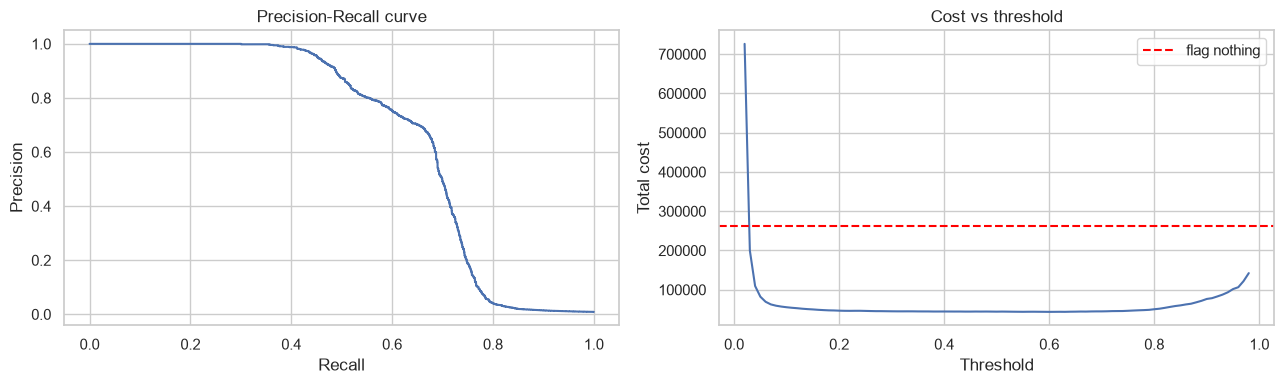

In [33]:
from sklearn.metrics import precision_recall_curve

best_model, proba = models["d4_sqrt_weight"]
y = y_val.values
amounts = val_df["TX_AMOUNT"].values

# Assumption: a missed fraud loses its full amount; a false alarm costs a fixed friction amount
FP_COST = 5.0   # change this to test different assumptions

rows = []
for t in np.linspace(0.02, 0.98, 97):
    pred = proba >= t
    tp = (pred & (y == 1)).sum()
    fp = (pred & (y == 0)).sum()
    missed = (~pred) & (y == 1)
    precision = tp / max(pred.sum(), 1)
    recall = tp / (y == 1).sum()
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    cost = amounts[missed].sum() + fp * FP_COST
    rows.append((t, precision, recall, f1, fp, missed.sum(), cost))

res_t = pd.DataFrame(rows, columns=["threshold", "precision", "recall", "f1", "false_pos", "missed_fraud", "cost"])
no_model_cost = amounts[y == 1].sum()

print("Cost if we flag nothing:", round(no_model_cost))
print("\nBest F1 threshold:")
print(res_t.loc[res_t["f1"].idxmax()].round(3).to_string())
print("\nBest cost threshold:")
print(res_t.loc[res_t["cost"].idxmin()].round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
prec, rec, _ = precision_recall_curve(y, proba)
ax[0].plot(rec, prec)
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision-Recall curve")
ax[1].plot(res_t["threshold"], res_t["cost"])
ax[1].axhline(no_model_cost, color="red", linestyle="--", label="flag nothing")
ax[1].set_xlabel("Threshold"); ax[1].set_ylabel("Total cost"); ax[1].set_title("Cost vs threshold")
ax[1].legend()
plt.tight_layout(); plt.show()

#### **Issues to keep in mind (short points)**

- `Recall ceiling of about 0.8`: roughly 20% of frauds are never caught at any threshold. My guess (not verified yet) is first-week-of-compromise transactions, whose labels aren’t confirmed because of the 7-day delay.
- `Optimistic validation scores`: early stopping and the threshold choice both used the validation set. The test set is the honest check, and it’s still untouched.
- `FP_COST = 5 is a placeholder`: the amounts in this simulated data have no real currency, so the cost view is for comparing thresholds, not real money.
- `Flat cost curve`: total cost barely changes from about 0.1 to 0.8, so the exact threshold isn’t critical.
- `Default 0.5 is not the best choice`: it gave about 7,800 false alarms with the older model, so we pick a threshold deliberately.

Threshold sensitivity to false-alarm cost

In [34]:
for fp_cost in [1, 5, 20, 50, 100]:
    costs = []
    for t in res_t["threshold"]:
        pred = proba >= t
        fp = (pred & (y == 0)).sum()
        missed = (~pred) & (y == 1)
        costs.append(amounts[missed].sum() + fp * fp_cost)
    costs = np.array(costs)
    best_t = res_t["threshold"].values[costs.argmin()]
    print(f"FP_COST={fp_cost:>3} | best threshold={best_t:.2f} | "
          f"cost={costs.min():,.0f} | flag-nothing={no_model_cost:,.0f}")

FP_COST=  1 | best threshold=0.07 | cost=34,246 | flag-nothing=263,198
FP_COST=  5 | best threshold=0.60 | cost=43,588 | flag-nothing=263,198
FP_COST= 20 | best threshold=0.74 | cost=56,149 | flag-nothing=263,198
FP_COST= 50 | best threshold=0.78 | cost=75,965 | flag-nothing=263,198
FP_COST=100 | best threshold=0.93 | cost=96,240 | flag-nothing=263,198


Final evaluation on the untouched test set


In [35]:
THRESHOLD = 0.7   # locked from validation; do not change after seeing test results

final_model = models["d4_sqrt_weight"][0]

test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)

print("TEST PR-AUC :", round(average_precision_score(y_test, test_proba), 4))
print("TEST ROC-AUC:", round(roc_auc_score(y_test, test_proba), 4))
print("\nConfusion matrix @ %.2f:\n" % THRESHOLD, confusion_matrix(y_test, test_pred))
print("\n", classification_report(y_test, test_pred, digits=3))

# Cost view (same assumptions as validation)
t_amt = test_df["TX_AMOUNT"].values
yt = y_test.values
missed = (test_pred == 0) & (yt == 1)
fp = ((test_pred == 1) & (yt == 0)).sum()
for fp_cost in [5, 20]:
    cost = t_amt[missed].sum() + fp * fp_cost
    print(f"FP_COST={fp_cost}: model cost={cost:,.0f} | flag-nothing={t_amt[yt == 1].sum():,.0f}")

# Recall by fraud scenario
r = test_df[["TX_FRAUD", "TX_FRAUD_SCENARIO"]].copy()
r["caught"] = test_pred
print(r[r["TX_FRAUD"] == 1].groupby("TX_FRAUD_SCENARIO")["caught"].agg(n_fraud="size", recall="mean").round(3))

TEST PR-AUC : 0.6641
TEST ROC-AUC: 0.8765

Confusion matrix @ 0.70:
 [[218198    733]
 [   639   1309]]

               precision    recall  f1-score   support

           0      0.997     0.997     0.997    218931
           1      0.641     0.672     0.656      1948

    accuracy                          0.994    220879
   macro avg      0.819     0.834     0.827    220879
weighted avg      0.994     0.994     0.994    220879

FP_COST=5: model cost=46,999 | flag-nothing=248,292
FP_COST=20: model cost=57,994 | flag-nothing=248,292
                   n_fraud  recall
TX_FRAUD_SCENARIO                 
1                      117   1.000
2                     1253   0.661
3                      578   0.630


Global feature importance with SHAP - SHapley Additive exPlanations

C:\Users\subay\AppData\Local\Temp\ipykernel_9044\3243547652.py:10: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, sample)


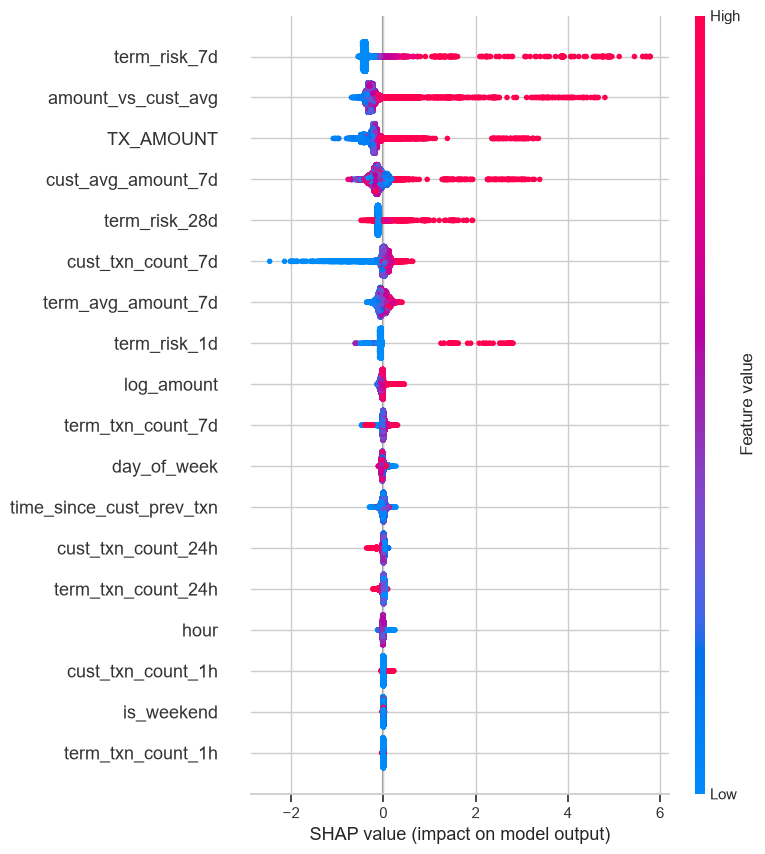

C:\Users\subay\AppData\Local\Temp\ipykernel_9044\3243547652.py:25: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, sample)


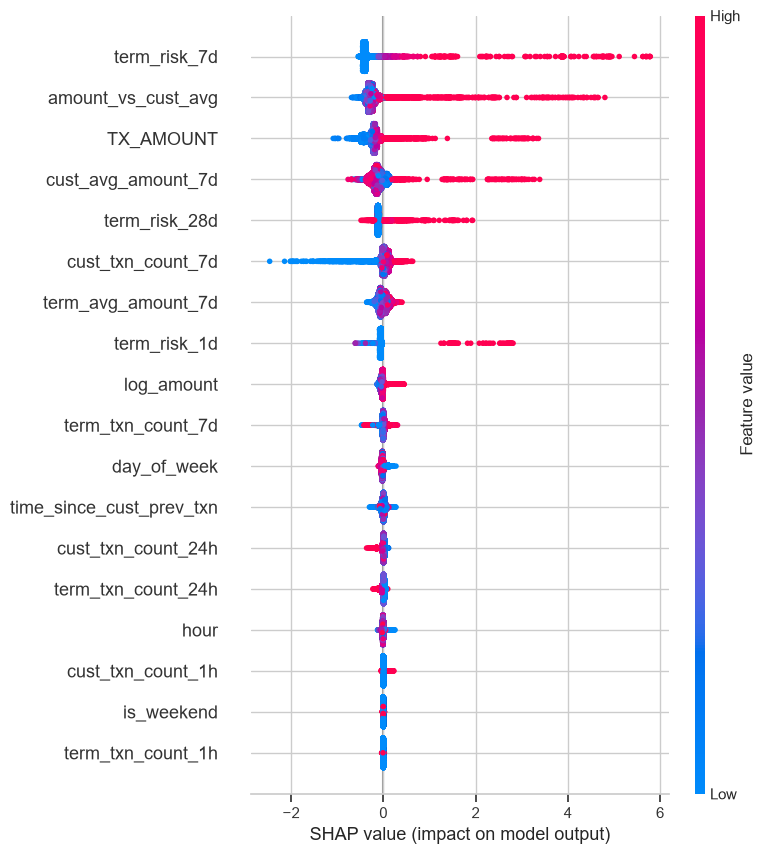

term_risk_7d                0.4166
amount_vs_cust_avg          0.2947
TX_AMOUNT                   0.2553
cust_avg_amount_7d          0.1594
term_risk_28d               0.1183
cust_txn_count_7d           0.0934
term_avg_amount_7d          0.0821
term_risk_1d                0.0594
log_amount                  0.0379
term_txn_count_7d           0.0333
day_of_week                 0.0320
time_since_cust_prev_txn    0.0313
cust_txn_count_24h          0.0264
term_txn_count_24h          0.0232
hour                        0.0147
cust_txn_count_1h           0.0048
is_weekend                  0.0013
term_txn_count_1h           0.0007
dtype: float32
term_risk_7d                0.4166
amount_vs_cust_avg          0.2947
TX_AMOUNT                   0.2553
cust_avg_amount_7d          0.1594
term_risk_28d               0.1183
cust_txn_count_7d           0.0934
term_avg_amount_7d          0.0821
term_risk_1d                0.0594
log_amount                  0.0379
term_txn_count_7d           0.0333
day_o

In [36]:
import shap

explainer = shap.TreeExplainer(final_model)

# Sample 20k test rows (explaining all 220k would be slow and unnecessary)
sample = X_test.sample(20000, random_state=42)
shap_values = explainer.shap_values(sample)

# 1) Beeswarm: direction and strength of each feature's effect
shap.summary_plot(shap_values, sample)

# 2) Ranked table: average absolute impact per feature
explainer = shap.TreeExplainer(final_model)

# Sample 20k test rows; explaining all rows would be slow
sample = X_test.sample(20000, random_state=42)

shap_values = np.asarray(explainer(sample).values)

# Some SHAP versions return values for both classes
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

# Beeswarm: direction and strength of each feature's effect
shap.summary_plot(shap_values, sample)

# Ranked table: average absolute impact per feature
imp = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=sample.columns
).sort_values(ascending=False)

print(imp.round(4))
print(imp.round(4))

Explain a single transaction

Transaction 1546297 | fraud risk: 98.6% | actual label: 1


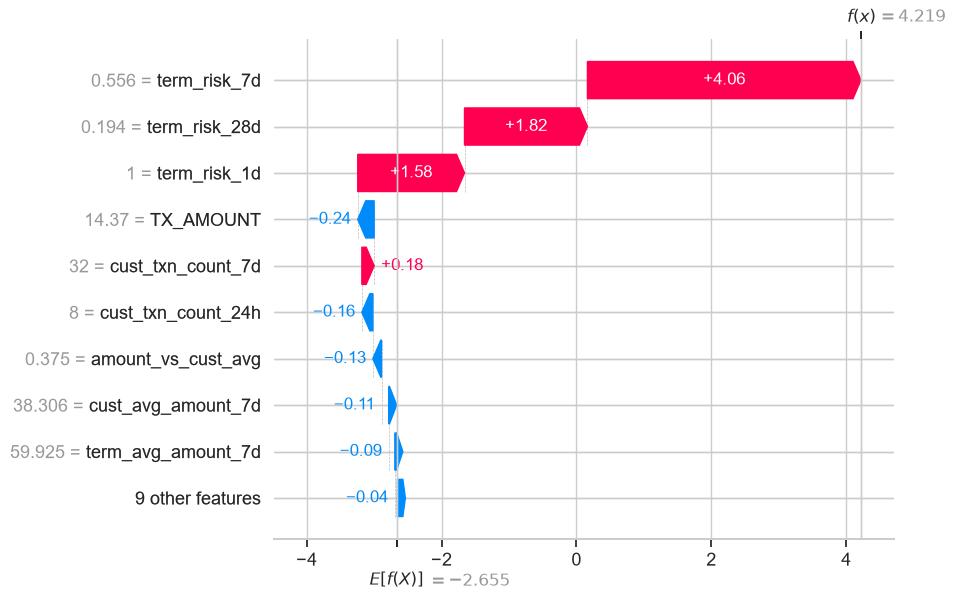


Main contributing factors:
  ↑ raises risk  term_risk_7d = 0.556  (impact +4.06)
  ↑ raises risk  term_risk_28d = 0.194  (impact +1.82)
  ↑ raises risk  term_risk_1d = 1.000  (impact +1.58)
  ↓ lowers risk  TX_AMOUNT = 14.370  (impact -0.24)
  ↑ raises risk  cust_txn_count_7d = 32.000  (impact +0.18)
Transaction 1567077 | fraud risk: 88.2% | actual label: 0


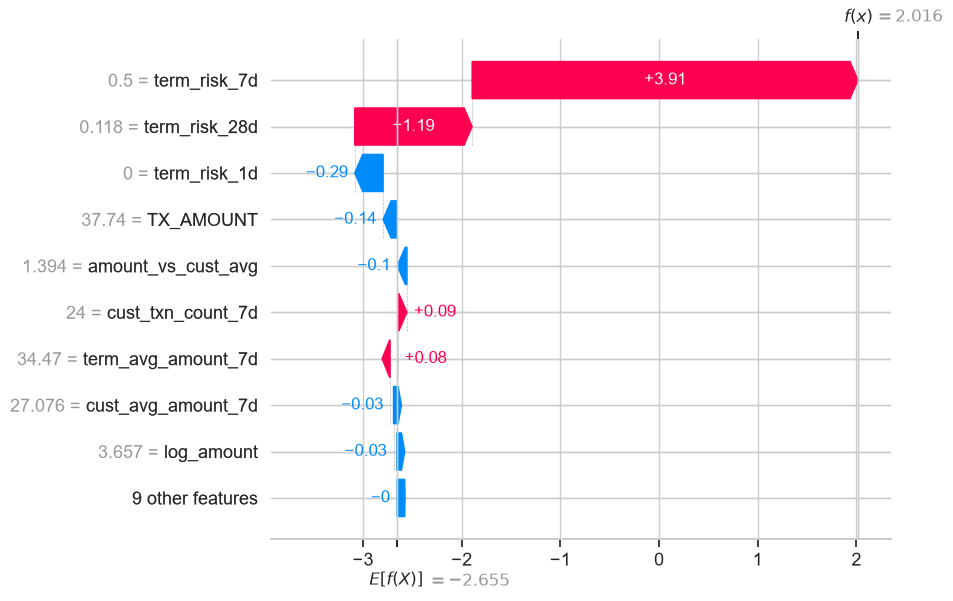


Main contributing factors:
  ↑ raises risk  term_risk_7d = 0.500  (impact +3.91)
  ↑ raises risk  term_risk_28d = 0.118  (impact +1.19)
  ↓ lowers risk  term_risk_1d = 0.000  (impact -0.29)
  ↓ lowers risk  TX_AMOUNT = 37.740  (impact -0.14)
  ↓ lowers risk  amount_vs_cust_avg = 1.394  (impact -0.10)


In [37]:
test_eval = test_df[["TX_FRAUD", "TX_FRAUD_SCENARIO"]].copy()
test_eval["proba"] = test_proba
test_eval["pred"] = test_pred

def explain(idx, top=5):
    row = X_test.loc[[idx]]
    exp = explainer(row)
    p = final_model.predict_proba(row)[0, 1]
    print(f"Transaction {idx} | fraud risk: {p:.1%} | actual label: {test_eval.loc[idx, 'TX_FRAUD']}")
    shap.plots.waterfall(exp[0], max_display=10)
    contrib = pd.Series(exp.values[0], index=row.columns)
    contrib = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(top)
    print("\nMain contributing factors:")
    for f, v in contrib.items():
        arrow = "↑ raises risk" if v > 0 else "↓ lowers risk"
        print(f"  {arrow:14s} {f} = {row[f].values[0]:.3f}  (impact {v:+.2f})")

# Example 1: a correctly caught Scenario 2 fraud (middle-scoring, so not a cherry-picked easy one)
tp = test_eval[(test_eval.TX_FRAUD == 1) & (test_eval.pred == 1) & (test_eval.TX_FRAUD_SCENARIO == 2)]
explain(tp.sort_values("proba").index[len(tp) // 2])

# Example 2: a false alarm (legit transaction we flagged)
fp = test_eval[(test_eval.TX_FRAUD == 0) & (test_eval.pred == 1)]
explain(fp.sort_values("proba").index[len(fp) // 2])

Add terminal trend features and compare on validation only

In [38]:
# 1) Trend features: is the terminal's risk rising or falling?
df["term_risk_trend_1_7"] = df["term_risk_1d"] - df["term_risk_7d"]     # the one you asked for
df["term_risk_trend_7_28"] = df["term_risk_7d"] - df["term_risk_28d"]   # same idea, one step older

# 2) Rebuild splits (new columns flow into X automatically)
train_df = df[df["TX_DATETIME"] < train_end].copy()
val_df = df[(df["TX_DATETIME"] >= val_start) & (df["TX_DATETIME"] < val_end)].copy()
X_train = train_df.drop(columns=drop_cols); y_train = train_df["TX_FRAUD"]
X_val = val_df.drop(columns=drop_cols);     y_val = val_df["TX_FRAUD"]
print("Features:", X_train.shape[1])

# 3) Check my hypothesis on the OLD model: are false alarms mostly "risk was in the old window only"?
old_proba = models["d4_sqrt_weight"][1]
flag = old_proba >= 0.7
fp_mask = flag & (y_val.values == 0)
tp_mask = flag & (y_val.values == 1)
print("\nShare with term_risk_1d == 0:")
print("  false alarms:", round((val_df["term_risk_1d"].values[fp_mask] == 0).mean(), 3))
print("  true catches:", round((val_df["term_risk_1d"].values[tp_mask] == 0).mean(), 3))

# 4) Retrain with the SAME settings as the best model
new_model = XGBClassifier(
    n_estimators=600, learning_rate=0.05, max_depth=4, min_child_weight=100,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=10,
    scale_pos_weight=np.sqrt(spw), tree_method="hist", eval_metric="aucpr",
    early_stopping_rounds=50, n_jobs=-1, random_state=42,
)
new_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
new_proba = new_model.predict_proba(X_val)[:, 1]

print("\nOLD  | PR-AUC: %.4f | ROC-AUC: %.4f" % (average_precision_score(y_val, old_proba), roc_auc_score(y_val, old_proba)))
print("NEW  | PR-AUC: %.4f | ROC-AUC: %.4f | best_iter: %d" % (
    average_precision_score(y_val, new_proba), roc_auc_score(y_val, new_proba), new_model.best_iteration))

# 5) Cost and false alarms, old vs new, at the best threshold for each
yv, av = y_val.values, val_df["TX_AMOUNT"].values
for name, pr in [("OLD", old_proba), ("NEW", new_proba)]:
    for fp_cost in [5, 20]:
        best = None
        for t in np.linspace(0.05, 0.95, 91):
            pred = pr >= t
            fp = (pred & (yv == 0)).sum()
            cost = av[(~pred) & (yv == 1)].sum() + fp * fp_cost
            if best is None or cost < best[1]:
                best = (t, cost, fp, (pred & (yv == 1)).sum())
        print(f"{name} FP_COST={fp_cost:>2} | best t={best[0]:.2f} | cost={best[1]:,.0f} | false alarms={best[2]} | caught={best[3]}")

Features: 20

Share with term_risk_1d == 0:
  false alarms: 0.618
  true catches: 0.587

OLD  | PR-AUC: 0.6683 | ROC-AUC: 0.8818
NEW  | PR-AUC: 0.6836 | ROC-AUC: 0.8798 | best_iter: 227
OLD FP_COST= 5 | best t=0.60 | cost=43,588 | false alarms=955 | caught=1404
OLD FP_COST=20 | best t=0.74 | cost=56,149 | false alarms=692 | caught=1375
NEW FP_COST= 5 | best t=0.62 | cost=43,670 | false alarms=855 | caught=1400
NEW FP_COST=20 | best t=0.75 | cost=54,281 | false alarms=509 | caught=1355


One-time test confirmation (threshold fixed at 0.7)

In [39]:
test_df = df[df["TX_DATETIME"] >= test_start].copy()
X_test = test_df.drop(columns=drop_cols); y_test = test_df["TX_FRAUD"]

THRESHOLD = 0.7   # unchanged from before
p_new = new_model.predict_proba(X_test)[:, 1]
pred_new = (p_new >= THRESHOLD).astype(int)

print("TEST PR-AUC : %.4f   (old model: 0.6641)" % average_precision_score(y_test, p_new))
print("TEST ROC-AUC: %.4f   (old model: 0.8765)" % roc_auc_score(y_test, p_new))
print("\nConfusion matrix @ 0.70 (old: FP=733, TP=1309):\n", confusion_matrix(y_test, pred_new))
print("\n", classification_report(y_test, pred_new, digits=3))

yt, at = y_test.values, test_df["TX_AMOUNT"].values
fp = ((pred_new == 1) & (yt == 0)).sum()
missed = (pred_new == 0) & (yt == 1)
for fp_cost, old in [(5, 46999), (20, 57994)]:
    print(f"FP_COST={fp_cost}: new cost={at[missed].sum() + fp * fp_cost:,.0f} (old: {old:,})")

r = test_df[["TX_FRAUD", "TX_FRAUD_SCENARIO"]].copy()
r["caught"] = pred_new
print(r[r.TX_FRAUD == 1].groupby("TX_FRAUD_SCENARIO")["caught"].agg(n_fraud="size", recall="mean").round(3))

TEST PR-AUC : 0.6822   (old model: 0.6641)
TEST ROC-AUC: 0.8775   (old model: 0.8765)

Confusion matrix @ 0.70 (old: FP=733, TP=1309):
 [[218310    621]
 [   636   1312]]

               precision    recall  f1-score   support

           0      0.997     0.997     0.997    218931
           1      0.679     0.674     0.676      1948

    accuracy                          0.994    220879
   macro avg      0.838     0.835     0.837    220879
weighted avg      0.994     0.994     0.994    220879

FP_COST=5: new cost=45,682 (old: 46,999)
FP_COST=20: new cost=54,997 (old: 57,994)
                   n_fraud  recall
TX_FRAUD_SCENARIO                 
1                      117   1.000
2                     1253   0.660
3                      578   0.637


#### **Save the model, feature list, threshold and a demo sample**

In [40]:
import os, json

os.makedirs("artifacts", exist_ok=True)

# 1) Save the model, keeping only the trees up to the best iteration
#    (early stopping trains 50 extra trees past the best one; we drop them so
#    prediction and SHAP both use exactly the model we evaluated)
best_booster = new_model.get_booster()[: new_model.best_iteration + 1]
best_booster.save_model("artifacts/fraud_xgb.json")

# 2) Save the settings the app needs
meta = {
    "features": list(X_train.columns),
    "threshold": 0.7,
    "best_iteration": int(new_model.best_iteration),
    "test_pr_auc": 0.6822,
}
with open("artifacts/meta.json", "w") as f:
    json.dump(meta, f, indent=2)

# 3) Save a demo sample from the TEST set (mix of fraud and legit, so the demo has interesting cases)
rng = np.random.RandomState(42)
fraud_idx = rng.choice(test_df.index[test_df["TX_FRAUD"] == 1], 500, replace=False)
legit_idx = rng.choice(test_df.index[test_df["TX_FRAUD"] == 0], 1500, replace=False)
demo = test_df.loc[np.concatenate([fraud_idx, legit_idx])]
demo_cols = ["TRANSACTION_ID", "TX_DATETIME", "CUSTOMER_ID", "TERMINAL_ID", "TX_AMOUNT", "TX_FRAUD"] + meta["features"]
demo = demo[demo_cols].drop(columns=["TX_AMOUNT"]).assign(TX_AMOUNT=demo["TX_AMOUNT"]) if False else demo[list(dict.fromkeys(demo_cols))]
demo.sample(frac=1, random_state=42).to_csv("artifacts/demo_transactions.csv", index=False)

# 4) Round-trip check: reload from disk and confirm identical predictions and a working SHAP explainer
loaded = XGBClassifier()
loaded.load_model("artifacts/fraud_xgb.json")

p_orig = new_model.predict_proba(X_test)[:, 1]
p_load = loaded.predict_proba(X_test[meta["features"]])[:, 1]
print("Max prediction difference after reload:", float(np.abs(p_orig - p_load).max()))

explainer_new = shap.TreeExplainer(loaded)
baseline = np.asarray(explainer_new.expected_value).reshape(-1)[0]
print("SHAP explainer ready. Baseline (log-odds):", round(float(baseline), 3))
print("Saved:", os.listdir("artifacts"))

Max prediction difference after reload: 0.0
SHAP explainer ready. Baseline (log-odds): -1.669
Saved: ['demo_transactions.csv', 'fraud_xgb.json', 'meta.json', 'test_metrics.json']


In [41]:
import json

THRESHOLD = 0.7
p = new_model.predict_proba(X_test)[:, 1]
pred = (p >= THRESHOLD).astype(int)
yt, at = y_test.values, test_df["TX_AMOUNT"].values

tp = int(((pred == 1) & (yt == 1)).sum()); fp = int(((pred == 1) & (yt == 0)).sum())
fn = int(((pred == 0) & (yt == 1)).sum()); tn = int(((pred == 0) & (yt == 0)).sum())
missed_amt = float(at[(pred == 0) & (yt == 1)].sum())
precision, recall = tp / (tp + fp), tp / (tp + fn)

metrics = {
    "threshold": THRESHOLD,
    "pr_auc": float(average_precision_score(y_test, p)),
    "roc_auc": float(roc_auc_score(y_test, p)),
    "precision": precision, "recall": recall,
    "f1": 2 * precision * recall / (precision + recall),
    "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    "cost5": missed_amt + fp * 5, "cost20": missed_amt + fp * 20,
    "nothing": float(at[yt == 1].sum()),
}
json.dump(metrics, open("artifacts/test_metrics.json", "w"), indent=2)
print(metrics)

{'threshold': 0.7, 'pr_auc': 0.682216896234383, 'roc_auc': 0.8774673817091649, 'precision': 0.6787377133988619, 'recall': 0.6735112936344969, 'f1': 0.6761144035042514, 'tp': 1312, 'fp': 621, 'fn': 636, 'tn': 218310, 'cost5': 45681.71875, 'cost20': 54996.71875, 'nothing': 248292.109375}


Preprocessing for the neural network and autoencoder

In [42]:
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

tf.keras.utils.set_random_seed(42)
assert X_train.shape[1] == 20, "Re-run the split block so X_train has the 20 features"

# Heavy-tailed, non-negative columns get a log transform first
log_cols = ["TX_AMOUNT", "cust_avg_amount_7d", "time_since_cust_prev_txn", "term_avg_amount_7d",
            "amount_vs_cust_avg",
            "cust_txn_count_1h", "cust_txn_count_24h", "cust_txn_count_7d",
            "term_txn_count_1h", "term_txn_count_24h", "term_txn_count_7d"]

def prep(X):
    X = X.copy()
    X[log_cols] = np.log1p(X[log_cols])
    return X

scaler_dl = StandardScaler().fit(prep(X_train))        # learn mean/spread from TRAIN only
Xtr = scaler_dl.transform(prep(X_train)).astype("float32")
Xva = scaler_dl.transform(prep(X_val)).astype("float32")
Xte = scaler_dl.transform(prep(X_test)).astype("float32")

print("Shapes:", Xtr.shape, Xva.shape, Xte.shape)
print(pd.DataFrame(Xtr, columns=X_train.columns).describe().loc[["mean", "std", "min", "max"]].round(2).T)

Shapes: (1169694, 20) (229581, 20) (220879, 20)
                          mean  std    min    max
TX_AMOUNT                  0.0  1.0  -3.97   3.60
hour                      -0.0  1.0  -2.27   2.27
day_of_week                0.0  1.0  -1.48   1.49
is_weekend                -0.0  1.0  -0.63   1.58
log_amount                 0.0  1.0  -3.97   3.60
cust_txn_count_1h          0.0  1.0  -0.38   6.89
cust_txn_count_24h         0.0  1.0  -1.95   2.64
cust_txn_count_7d         -0.0  1.0  -4.68   1.97
cust_avg_amount_7d         0.0  1.0  -5.23   3.71
time_since_cust_prev_txn   0.0  1.0  -6.43   4.22
amount_vs_cust_avg         0.0  1.0  -2.63  21.02
term_txn_count_1h         -0.0  1.0  -0.23   8.56
term_txn_count_24h         0.0  1.0  -1.15   3.87
term_txn_count_7d         -0.0  1.0  -4.19   2.78
term_avg_amount_7d        -0.0  1.0 -10.15   7.09
term_risk_1d               0.0  1.0  -0.07  15.25
term_risk_7d              -0.0  1.0  -0.11  14.49
term_risk_28d             -0.0  1.0  -0.13  18.30
te

Train the neural network

In [43]:
from tensorflow import keras
from tensorflow.keras import layers
import time

spw_nn = np.sqrt((y_train == 0).sum() / (y_train == 1).sum())   # soft class weight, as in the best XGBoost run
print("Fraud class weight:", round(float(spw_nn), 1))

nn = keras.Sequential([
    layers.Input(shape=(Xtr.shape[1],)),
    layers.Dense(128, activation="relu"), layers.Dropout(0.2),
    layers.Dense(64, activation="relu"), layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
nn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
           metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])

early = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=5, restore_best_weights=True)

start = time.time()
hist = nn.fit(Xtr, y_train.values, validation_data=(Xva, y_val.values),
              epochs=40, batch_size=2048, class_weight={0: 1.0, 1: float(spw_nn)},
              callbacks=[early], verbose=2)
print("Training time: %.0f sec | epochs run: %d" % (time.time() - start, len(hist.history["loss"])))

nn_val = nn.predict(Xva, batch_size=8192, verbose=0).ravel()
print("NN  VAL PR-AUC : %.4f   (XGBoost with trend features: 0.6836)" % average_precision_score(y_val, nn_val))
print("NN  VAL ROC-AUC: %.4f   (XGBoost: 0.8798)" % roc_auc_score(y_val, nn_val))

# Best-F1 threshold on validation (the NN's scores are on a different scale, so 0.7 isn't comparable)
prec, rec, thr = precision_recall_curve(y_val, nn_val)
f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
i = f1.argmax()
print("Best-F1 threshold %.2f | precision %.3f | recall %.3f | F1 %.3f" % (thr[i], prec[i], rec[i], f1[i]))

Fraud class weight: 11.1
Epoch 1/40
572/572 - 4s - 7ms/step - loss: 0.1970 - pr_auc: 0.4279 - val_loss: 0.0493 - val_pr_auc: 0.6106
Epoch 2/40
572/572 - 2s - 4ms/step - loss: 0.1524 - pr_auc: 0.5706 - val_loss: 0.0456 - val_pr_auc: 0.6503
Epoch 3/40
572/572 - 2s - 4ms/step - loss: 0.1454 - pr_auc: 0.6093 - val_loss: 0.0464 - val_pr_auc: 0.6729
Epoch 4/40
572/572 - 2s - 4ms/step - loss: 0.1411 - pr_auc: 0.6294 - val_loss: 0.0432 - val_pr_auc: 0.6752
Epoch 5/40
572/572 - 3s - 5ms/step - loss: 0.1387 - pr_auc: 0.6374 - val_loss: 0.0446 - val_pr_auc: 0.6826
Epoch 6/40
572/572 - 3s - 5ms/step - loss: 0.1376 - pr_auc: 0.6453 - val_loss: 0.0442 - val_pr_auc: 0.6866
Epoch 7/40
572/572 - 3s - 5ms/step - loss: 0.1362 - pr_auc: 0.6492 - val_loss: 0.0460 - val_pr_auc: 0.6900
Epoch 8/40
572/572 - 3s - 5ms/step - loss: 0.1351 - pr_auc: 0.6556 - val_loss: 0.0449 - val_pr_auc: 0.6885
Epoch 9/40
572/572 - 2s - 4ms/step - loss: 0.1346 - pr_auc: 0.6580 - val_loss: 0.0440 - val_pr_auc: 0.6889
Epoch 10/40


Fair comparison on validation (test set untouched)

In [44]:
yv = y_val.values
cands = {"XGBoost": new_proba, "Neural net": nn_val, "Average of both": (new_proba + nn_val) / 2}

def prec_at_recall(y, p, target):
    prec, rec, _ = precision_recall_curve(y, p)
    return prec[rec >= target].max()

for name, p in cands.items():
    line = f"{name:16s} PR-AUC {average_precision_score(yv, p):.4f} | ROC-AUC {roc_auc_score(yv, p):.4f}"
    for tgt in (0.5, 0.6, 0.7):
        line += f" | prec@recall{tgt}: {prec_at_recall(yv, p, tgt):.3f}"
    print(line)

XGBoost          PR-AUC 0.6836 | ROC-AUC 0.8798 | prec@recall0.5: 0.920 | prec@recall0.6: 0.884 | prec@recall0.7: 0.490
Neural net       PR-AUC 0.6979 | ROC-AUC 0.8768 | prec@recall0.5: 0.989 | prec@recall0.6: 0.933 | prec@recall0.7: 0.530
Average of both  PR-AUC 0.6968 | ROC-AUC 0.8802 | prec@recall0.5: 0.968 | prec@recall0.6: 0.918 | prec@recall0.7: 0.520


Autoencoder (anomaly detection)

In [45]:
Xtr_legit = Xtr[y_train.values == 0]
Xva_legit = Xva[y_val.values == 0]
d = Xtr.shape[1]

ae = keras.Sequential([
    layers.Input(shape=(d,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(4, activation="relu"),      # bottleneck: forces a compressed summary of "normal"
    layers.Dense(8, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(d, activation="linear"),
])
ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")

early_ae = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
start = time.time()
h = ae.fit(Xtr_legit, Xtr_legit, validation_data=(Xva_legit, Xva_legit),
           epochs=30, batch_size=2048, callbacks=[early_ae], verbose=0)
print("Training time: %.0f sec | epochs: %d | best val loss: %.4f" % (time.time() - start, len(h.history["loss"]), min(h.history["val_loss"])))

def recon_error(X):
    R = ae.predict(X, batch_size=8192, verbose=0)
    return ((X - R) ** 2).mean(axis=1)       # average squared reconstruction error per row

ae_val = recon_error(Xva)
print("AE  VAL PR-AUC : %.4f   (NN 0.6979 | XGBoost 0.6836)" % average_precision_score(yv, ae_val))
print("AE  VAL ROC-AUC: %.4f   (NN 0.8768 | XGBoost 0.8798)" % roc_auc_score(yv, ae_val))

# Which fraud types does it notice? (scenario used for analysis only)
sc = val_df["TX_FRAUD_SCENARIO"].values
print("\nROC-AUC, each fraud type vs legit:   AE | NN | XGBoost")
for s in (1, 2, 3):
    m = (sc == s) | (yv == 0)
    lab = (sc[m] == s).astype(int)
    print(f"  Scenario {s}: {roc_auc_score(lab, ae_val[m]):.3f} | {roc_auc_score(lab, nn_val[m]):.3f} | {roc_auc_score(lab, new_proba[m]):.3f}")

Training time: 33 sec | epochs: 30 | best val loss: 0.2400
AE  VAL PR-AUC : 0.1569   (NN 0.6979 | XGBoost 0.6836)
AE  VAL ROC-AUC: 0.7764   (NN 0.8768 | XGBoost 0.8798)

ROC-AUC, each fraud type vs legit:   AE | NN | XGBoost
  Scenario 1: 0.533 | 1.000 | 0.999
  Scenario 2: 0.829 | 0.845 | 0.844
  Scenario 3: 0.719 | 0.917 | 0.928


Seed stability check (validation only)

In [46]:
def build_nn():
    m = keras.Sequential([
        layers.Input(shape=(Xtr.shape[1],)),
        layers.Dense(128, activation="relu"), layers.Dropout(0.2),
        layers.Dense(64, activation="relu"), layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
    return m

nn_runs = [average_precision_score(yv, nn_val)]        # seed 42, from before
xgb_runs = [average_precision_score(yv, new_proba)]    # random_state 42, from before

for seed in (1, 2, 3):
    tf.keras.utils.set_random_seed(seed)
    m = build_nn()
    m.fit(Xtr, y_train.values, validation_data=(Xva, y_val.values), epochs=40, batch_size=2048,
          class_weight={0: 1.0, 1: float(spw_nn)}, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=5, restore_best_weights=True)])
    nn_runs.append(average_precision_score(yv, m.predict(Xva, batch_size=8192, verbose=0).ravel()))

    xm = XGBClassifier(
        n_estimators=600, learning_rate=0.05, max_depth=4, min_child_weight=100,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=10, scale_pos_weight=np.sqrt(spw),
        tree_method="hist", eval_metric="aucpr", early_stopping_rounds=50, n_jobs=-1, random_state=seed)
    xm.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    xgb_runs.append(average_precision_score(yv, xm.predict_proba(X_val)[:, 1]))
    print(f"seed {seed} done | NN {nn_runs[-1]:.4f} | XGB {xgb_runs[-1]:.4f}")

print("\nNN  runs:", np.round(nn_runs, 4), "| mean %.4f | std %.4f" % (np.mean(nn_runs), np.std(nn_runs)))
print("XGB runs:", np.round(xgb_runs, 4), "| mean %.4f | std %.4f" % (np.mean(xgb_runs), np.std(xgb_runs)))

seed 1 done | NN 0.6986 | XGB 0.6853
seed 2 done | NN 0.6984 | XGB 0.6834
seed 3 done | NN 0.6980 | XGB 0.6849

NN  runs: [0.6979 0.6986 0.6984 0.698 ] | mean 0.6982 | std 0.0003
XGB runs: [0.6836 0.6853 0.6834 0.6849] | mean 0.6843 | std 0.0008


Final head-to-head on the test set

In [47]:
def best_t(p, y, amt, fp_cost):
    ts = np.linspace(0.02, 0.98, 97)
    costs = [amt[(p < t) & (y == 1)].sum() + ((p >= t) & (y == 0)).sum() * fp_cost for t in ts]
    return ts[int(np.argmin(costs))]

def eval_at(p, y, amt, t, fp_cost):
    pred = p >= t
    tp = (pred & (y == 1)).sum(); fp = (pred & (y == 0)).sum(); fn = ((~pred) & (y == 1)).sum()
    return tp, fp, fn, amt[(~pred) & (y == 1)].sum() + fp * fp_cost

amt_v, amt_t, yt = val_df["TX_AMOUNT"].values, test_df["TX_AMOUNT"].values, y_test.values
nn_test = nn.predict(Xte, batch_size=8192, verbose=0).ravel()
pairs = {"XGBoost": (new_proba, p_new), "Neural net": (nn_val, nn_test)}

print("TEST PR-AUC | XGBoost %.4f | Neural net %.4f" % (average_precision_score(yt, p_new), average_precision_score(yt, nn_test)))
print("TEST ROC-AUC| XGBoost %.4f | Neural net %.4f" % (roc_auc_score(yt, p_new), roc_auc_score(yt, nn_test)))
print("No-detection cost: {:,.0f}\n".format(amt_t[yt == 1].sum()))
for fp_cost in (5, 20):
    for name, (pv, pt) in pairs.items():
        t = best_t(pv, yv, amt_v, fp_cost)
        tp, fp, fn, cost = eval_at(pt, yt, amt_t, t, fp_cost)
        print(f"FP_COST={fp_cost:>2} | {name:10s} | threshold {t:.2f} | caught {tp} | false alarms {fp} | missed {fn} | cost {cost:,.0f}")

TEST PR-AUC | XGBoost 0.6822 | Neural net 0.6963
TEST ROC-AUC| XGBoost 0.8775 | Neural net 0.8756
No-detection cost: 248,292

FP_COST= 5 | XGBoost    | threshold 0.62 | caught 1328 | false alarms 835 | missed 620 | cost 44,766
FP_COST= 5 | Neural net | threshold 0.38 | caught 1361 | false alarms 1246 | missed 587 | cost 44,435
FP_COST=20 | XGBoost    | threshold 0.75 | caught 1296 | false alarms 462 | missed 652 | cost 54,495
FP_COST=20 | Neural net | threshold 0.77 | caught 1251 | false alarms 296 | missed 697 | cost 55,809
